In [ ]:
# ALL IMPORTS & LIBRARIES CENTER
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.applications import InceptionV3, ResNet50
from sklearn.model_selection import KFold

print("--- STEP 1 BERHASIL ---")
print("Semua library yang dibutuhkan untuk UAS berhasil dimuat dalam satu memori!")

--- STEP 1 BERHASIL ---
Semua library yang dibutuhkan untuk UAS berhasil dimuat dalam satu memori!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# LOCAL DATA SYNC & AUTOMATIC CATALOG

print("Menyalin 2.000 gambar sampel ke lokal Colab...")
os.system('cp -r /content/drive/MyDrive/UAS/ISIC_sample /content/sampled_dataset')

target_base_dir = '/content/sampled_dataset/'
class_columns = ['MEL', 'NV', 'BCC', 'AKIEC', 'BKL', 'DF', 'VASC']

data_list = []
for kelas in class_columns:
    folder_kelas = os.path.join(target_base_dir, kelas)
    if os.path.exists(folder_kelas):
        for file_name in os.listdir(folder_kelas):
            if file_name.lower().endswith('.jpg'):
                local_path = os.path.join(folder_kelas, file_name)
                data_list.append({'local_path': local_path, 'label': kelas})

df_sampled = pd.DataFrame(data_list)

print(f"\n--- RE-DOKUMENTASI BERHASIL ---")
print(f"Total gambar sampel yang siap digunakan: {len(df_sampled)} gambar.")
print("\nSebaran kelas sampel kamu (Tetap Seimbang & Proporsional):")
print(df_sampled['label'].value_counts())

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    vertical_flip=True,
    fill_mode='nearest'
)

val_datagen = ImageDataGenerator(rescale=1./255)

Menyalin 2.000 gambar sampel ke lokal Colab...

--- RE-DOKUMENTASI BERHASIL ---
Total gambar sampel yang siap digunakan: 2000 gambar.

Sebaran kelas sampel kamu (Tetap Seimbang & Proporsional):
label
NV       1339
MEL       222
BKL       220
BCC       103
AKIEC      65
VASC       28
DF         23
Name: count, dtype: int64


In [ ]:
# MODEL ARCHITECTURE BUILDER

# Fungsi Pembuat Model InceptionV3
def build_inception_model(num_classes=7):
    base_model = InceptionV3(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
    base_model.trainable = False
    x = base_model.output
    x = GlobalAveragePooling2D()(x)
    predictions = Dense(num_classes, activation='softmax')(x)
    model = Model(inputs=base_model.input, outputs=predictions)
    model.compile(optimizer=Adam(learning_rate=0.0001), loss='categorical_crossentropy', metrics=['accuracy'])
    return model

# Fungsi Pembuat Model ResNet50
def build_resnet_model(num_classes=7):
    base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
    base_model.trainable = False
    x = base_model.output
    x = GlobalAveragePooling2D()(x)
    predictions = Dense(num_classes, activation='softmax')(x)
    model = Model(inputs=base_model.input, outputs=predictions)
    model.compile(optimizer=Adam(learning_rate=0.0001), loss='categorical_crossentropy', metrics=['accuracy'])
    return model

print("Arsitektur fungsi InceptionV3 dan ResNet50 berhasil siap di memori!")

Arsitektur fungsi InceptionV3 dan ResNet50 berhasil siap di memori!


In [ ]:
# MASTER LOOP INCEPTIONV3 (5-FOLD x 10 EPOCHS)

inception_histories = []
inception_accuracies = []
inception_times = []

kf = KFold(n_splits=5, shuffle=True, random_state=42)
fold_number = 1

print("Memulai Eksperimen K-Fold InceptionV3 (10 Epochs per fold)...\n")

for train_index, val_index in kf.split(df_sampled):
    print(f"==========================================")
    print(f" INCEPTIONV3: FOLD {fold_number} / 5")
    print(f"==========================================")

    train_df = df_sampled.iloc[train_index]
    val_df = df_sampled.iloc[val_index]

    train_generator = train_datagen.flow_from_dataframe(
        dataframe=train_df, x_col='local_path', y_col='label',
        target_size=(224, 224), batch_size=32, class_mode='categorical', shuffle=True, verbose=0
    )

    val_generator = val_datagen.flow_from_dataframe(
        dataframe=val_df, x_col='local_path', y_col='label',
        target_size=(224, 224), batch_size=32, class_mode='categorical', shuffle=False, verbose=0
    )

    model_inception = build_inception_model(num_classes=7)

    # Catat waktu mulai
    start_time = time.time()

    history = model_inception.fit(
        train_generator, validation_data=val_generator,
        epochs=10, verbose=1 # Naik ke 10 Epochs
    )

    duration = time.time() - start_time
    inception_times.append(duration)

    val_loss, val_acc = model_inception.evaluate(val_generator, verbose=0)
    inception_accuracies.append(val_acc)
    inception_histories.append(history)

    print(f"\n>> Hasil Sementara Fold {fold_number}: Waktu = {duration:.2f}s, Acc = {val_acc*100:.2f}%\n")
    fold_number += 1

print("\n>> [SUKSES] K-Fold InceptionV3 Selesai!")

Memulai Eksperimen K-Fold InceptionV3 (10 Epochs per fold)...

 INCEPTIONV3: FOLD 1 / 5
Found 1600 validated image filenames belonging to 7 classes.
Found 400 validated image filenames belonging to 7 classes.
Epoch 1/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 55s 843ms/step - accuracy: 0.5275 - loss: 1.4359 - val_accuracy: 0.6450 - val_loss: 1.3094
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 31s 625ms/step - accuracy: 0.6725 - loss: 1.2019 - val_accuracy: 0.6400 - val_loss: 1.2386
Epoch 3/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 32s 633ms/step - accuracy: 0.6712 - loss: 1.1194 - val_accuracy: 0.6450 - val_loss: 1.1835
Epoch 4/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 32s 644ms/step - accuracy: 0.6719 - loss: 1.0534 - val_accuracy: 0.6475 - val_loss: 1.1297
Epoch 5/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 32s 640ms/step - accuracy: 0.6787 - loss: 1.0251 - val_accuracy: 0.6450 - val_loss: 1.0942
Epoch 6/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 31s 620ms/step - accuracy: 0.6725 - loss: 0.9840 - val_accuracy: 0.6525 - val_loss: 1.0638
Epoch 7/10
50/50 

In [ ]:
# MASTER LOOP RESNET50 (5-FOLD x 10 EPOCHS)

resnet_histories = []
resnet_accuracies = []
resnet_times = []

fold_number = 1
print("Memulai Eksperimen K-Fold ResNet50 (10 Epochs per fold)...\n")

for train_index, val_index in kf.split(df_sampled):
    print(f"==========================================")
    print(f" RESNET50: FOLD {fold_number} / 5")
    print(f"==========================================")

    train_df = df_sampled.iloc[train_index]
    val_df = df_sampled.iloc[val_index]

    train_generator = train_datagen.flow_from_dataframe(
        dataframe=train_df, x_col='local_path', y_col='label',
        target_size=(224, 224), batch_size=32, class_mode='categorical', shuffle=True, verbose=0
    )

    val_generator = val_datagen.flow_from_dataframe(
        dataframe=val_df, x_col='local_path', y_col='label',
        target_size=(224, 224), batch_size=32, class_mode='categorical', shuffle=False, verbose=0
    )

    model_resnet = build_resnet_model(num_classes=7)

    # Catat waktu mulai
    start_time = time.time()

    history = model_resnet.fit(
        train_generator, validation_data=val_generator,
        epochs=10, verbose=1 # Naik ke 10 Epochs
    )

    duration = time.time() - start_time
    resnet_times.append(duration)

    val_loss, val_acc = model_resnet.evaluate(val_generator, verbose=0)
    resnet_accuracies.append(val_acc)
    resnet_histories.append(history)

    print(f"\n>> Hasil Sementara Fold {fold_number}: Waktu = {duration:.2f}s, Acc = {val_acc*100:.2f}%\n")
    fold_number += 1

print("\n>> [SUKSES] K-Fold ResNet50 Selesai!")

Memulai Eksperimen K-Fold ResNet50 (10 Epochs per fold)...

 RESNET50: FOLD 1 / 5
Found 1600 validated image filenames belonging to 7 classes.
Found 400 validated image filenames belonging to 7 classes.
Epoch 1/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 47s 732ms/step - accuracy: 0.1725 - loss: 2.0431 - val_accuracy: 0.6500 - val_loss: 1.5877
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 32s 647ms/step - accuracy: 0.6744 - loss: 1.3414 - val_accuracy: 0.6500 - val_loss: 1.2611
Epoch 3/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 31s 615ms/step - accuracy: 0.6744 - loss: 1.1710 - val_accuracy: 0.6500 - val_loss: 1.2076
Epoch 4/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 31s 614ms/step - accuracy: 0.6744 - loss: 1.1405 - val_accuracy: 0.6500 - val_loss: 1.1928
Epoch 5/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 31s 618ms/step - accuracy: 0.6744 - loss: 1.1302 - val_accuracy: 0.6500 - val_loss: 1.1853
Epoch 6/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 33s 666ms/step - accuracy: 0.6744 - loss: 1.1262 - val_accuracy: 0.6500 - val_loss: 1.1813
Epoch 7/10
50/50 ━━━━━━

             TABEL HASIL EVALUASI KOMPARASI MODEL (UNTUK UAS)


,InceptionV3 Accuracy (%),InceptionV3 Time (Sec),ResNet50 Accuracy (%),ResNet50 Time (Sec)
Fold 1,65.75%,339.31s,65.00%,330.85s
Fold 2,71.75%,337.31s,71.00%,334.78s
Fold 3,64.75%,336.24s,64.00%,339.18s
Fold 4,72.00%,337.01s,70.25%,330.50s
Fold 5,67.50%,339.61s,64.50%,331.88s
KESIMPULAN AKHIR,68.35% (Rata-rata),337.90s (Rata-rata),66.95% (Rata-rata),333.44s (Rata-rata)


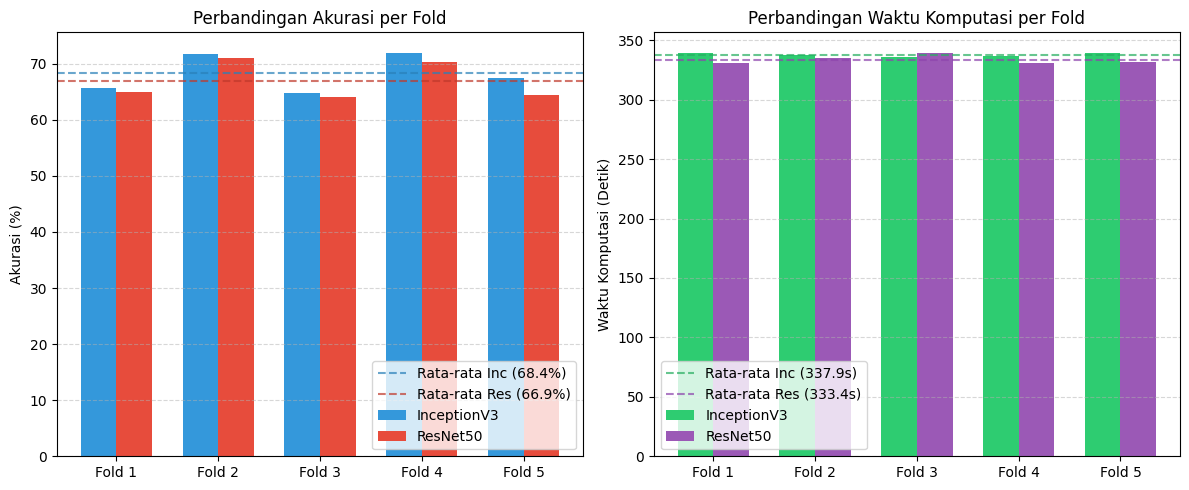

In [ ]:
# EVALUATION, COMPARISON TABLE & VISUALIZATION

# 1. MENGHITUNG RATA-RATA (MEAN) UNTUK MATRIKS UTAMA
mean_inc_acc = np.mean(inception_accuracies) * 100
mean_inc_time = np.mean(inception_times)

mean_res_acc = np.mean(resnet_accuracies) * 100
mean_res_time = np.mean(resnet_times)

# 2. MEMBUAT TABEL RINGKASAN DATA UNTUK LAPORAN
folds_range = [f"Fold {i+1}" for i in range(5)]

summary_data = {
    "InceptionV3 Accuracy (%)": [f"{acc*100:.2f}%" for acc in inception_accuracies] + [f"{mean_inc_acc:.2f}% (Rata-rata)"],
    "InceptionV3 Time (Sec)": [f"{t:.2f}s" for t in inception_times] + [f"{mean_inc_time:.2f}s (Rata-rata)"],
    "ResNet50 Accuracy (%)": [f"{acc*100:.2f}%" for acc in resnet_accuracies] + [f"{mean_res_acc:.2f}% (Rata-rata)"],
    "ResNet50 Time (Sec)": [f"{t:.2f}s" for t in resnet_times] + [f"{mean_res_time:.2f}s (Rata-rata)"]
}

row_names = folds_range + ["KESIMPULAN AKHIR"]
df_summary = pd.DataFrame(summary_data, index=row_names)

print("==========================================================================")
print("             TABEL HASIL EVALUASI KOMPARASI MODEL (UNTUK UAS)")
print("==========================================================================")
display(df_summary)
print("==========================================================================\n")

# 3. MEMBUAT GRAFIK PERBANDINGAN AKURASI (BAR CHART)
plt.figure(figsize=(12, 5))

# Subplot 1: Grafik Akurasi
plt.subplot(1, 2, 1)
x = np.arange(5)
width = 0.35
plt.bar(x - width/2, [a*100 for a in inception_accuracies], width, label='InceptionV3', color='#3498db')
plt.bar(x + width/2, [a*100 for a in resnet_accuracies], width, label='ResNet50', color='#e74c3c')
plt.axhline(y=mean_inc_acc, color='#2980b9', linestyle='--', alpha=0.7, label=f'Rata-rata Inc ({mean_inc_acc:.1f}%)')
plt.axhline(y=mean_res_acc, color='#c0392b', linestyle='--', alpha=0.7, label=f'Rata-rata Res ({mean_res_acc:.1f}%)')
plt.ylabel('Akurasi (%)')
plt.title('Perbandingan Akurasi per Fold')
plt.xticks(x, folds_range)
plt.legend(loc='lower right')
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Subplot 2: Grafik Waktu Komputasi
plt.subplot(1, 2, 2)
plt.bar(x - width/2, inception_times, width, label='InceptionV3', color='#2ecc71')
plt.bar(x + width/2, resnet_times, width, label='ResNet50', color='#9b59b6')
plt.axhline(y=mean_inc_time, color='#27ae60', linestyle='--', alpha=0.7, label=f'Rata-rata Inc ({mean_inc_time:.1f}s)')
plt.axhline(y=mean_res_time, color='#8e44ad', linestyle='--', alpha=0.7, label=f'Rata-rata Res ({mean_res_time:.1f}s)')
plt.ylabel('Waktu Komputasi (Detik)')
plt.title('Perbandingan Waktu Komputasi per Fold')
plt.xticks(x, folds_range)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

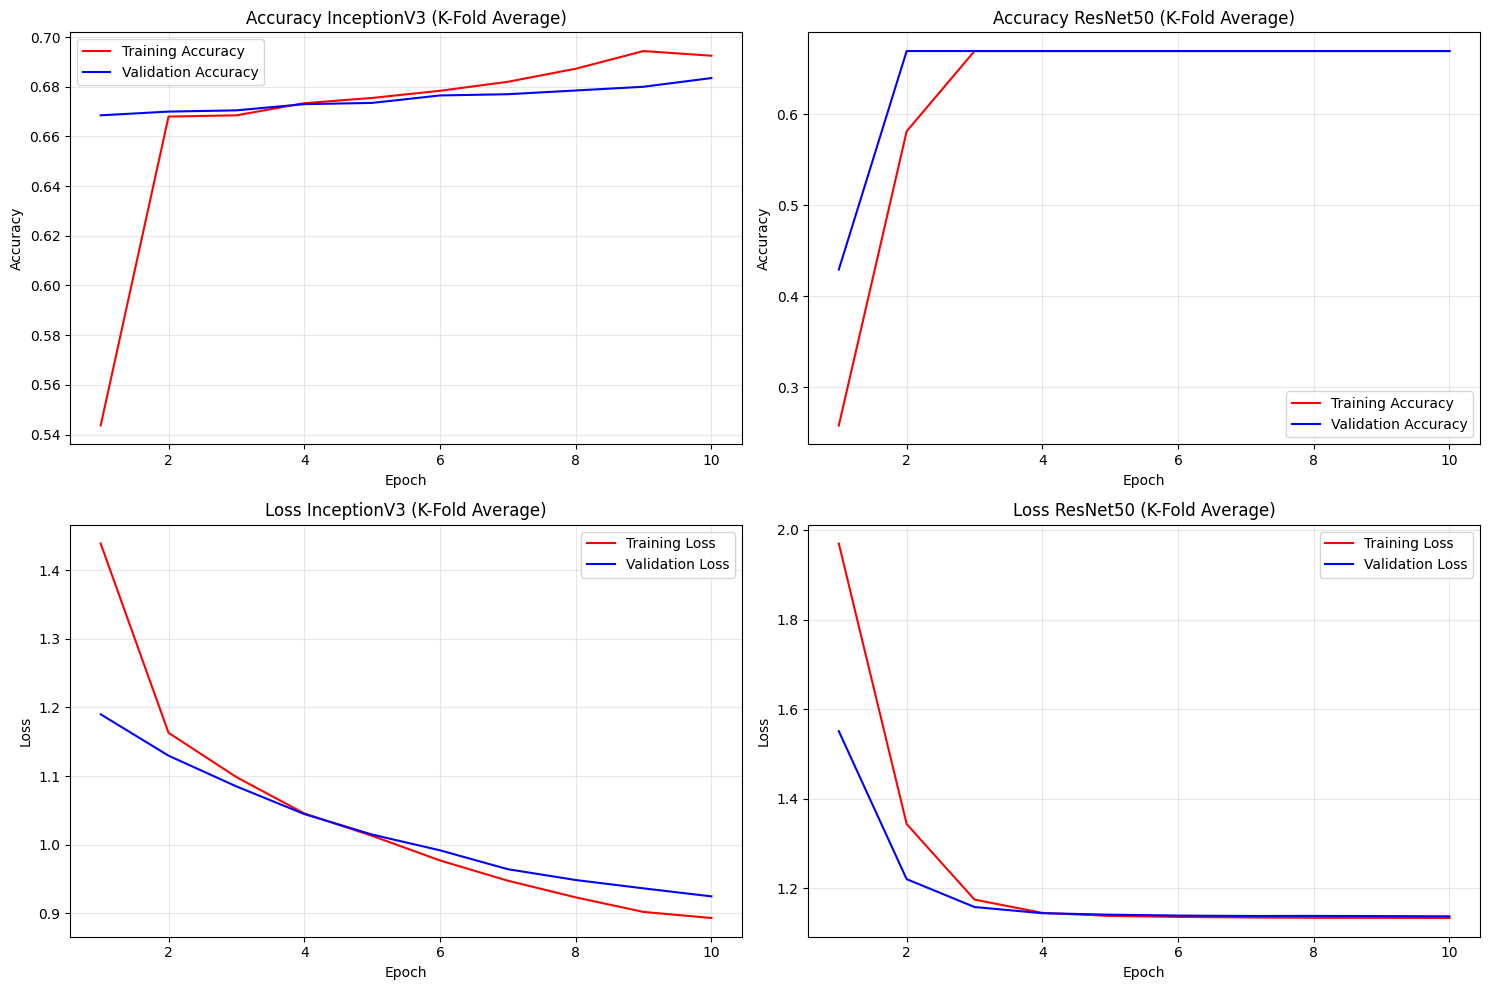

In [ ]:
# GRAPH LINEAR VISUALIZATION (K-FOLD AVERAGE)
epochs_range = range(1, 11)

# Hitung rata-rata performa dari 5 fold untuk tiap epoch-nya
avg_inc_train = np.mean([h.history['accuracy'] for h in inception_histories], axis=0)
avg_inc_val = np.mean([h.history['val_accuracy'] for h in inception_histories], axis=0)
avg_inc_loss = np.mean([h.history['loss'] for h in inception_histories], axis=0)
avg_inc_val_loss = np.mean([h.history['val_loss'] for h in inception_histories], axis=0)

avg_res_train = np.mean([h.history['accuracy'] for h in resnet_histories], axis=0)
avg_res_val = np.mean([h.history['val_accuracy'] for h in resnet_histories], axis=0)
avg_res_loss = np.mean([h.history['loss'] for h in resnet_histories], axis=0)
avg_res_val_loss = np.mean([h.history['val_loss'] for h in resnet_histories], axis=0)

plt.figure(figsize=(15, 10))

# [Kiri Atas] Accuracy InceptionV3
plt.subplot(2, 2, 1)
plt.plot(epochs_range, avg_inc_train, label='Training Accuracy', color='red')
plt.plot(epochs_range, avg_inc_val, label='Validation Accuracy', color='blue')
plt.title('Accuracy InceptionV3 (K-Fold Average)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)

# [Kanan Atas] Accuracy ResNet50
plt.subplot(2, 2, 2)
plt.plot(epochs_range, avg_res_train, label='Training Accuracy', color='red')
plt.plot(epochs_range, avg_res_val, label='Validation Accuracy', color='blue')
plt.title('Accuracy ResNet50 (K-Fold Average)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)

# [Kiri Bawah] Loss InceptionV3
plt.subplot(2, 2, 3)
plt.plot(epochs_range, avg_inc_loss, label='Training Loss', color='red')
plt.plot(epochs_range, avg_inc_val_loss, label='Validation Loss', color='blue')
plt.title('Loss InceptionV3 (K-Fold Average)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)

# [Kanan Bawah] Loss ResNet50
plt.subplot(2, 2, 4)
plt.plot(epochs_range, avg_res_loss, label='Training Loss', color='red')
plt.plot(epochs_range, avg_res_val_loss, label='Validation Loss', color='blue')
plt.title('Loss ResNet50 (K-Fold Average)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

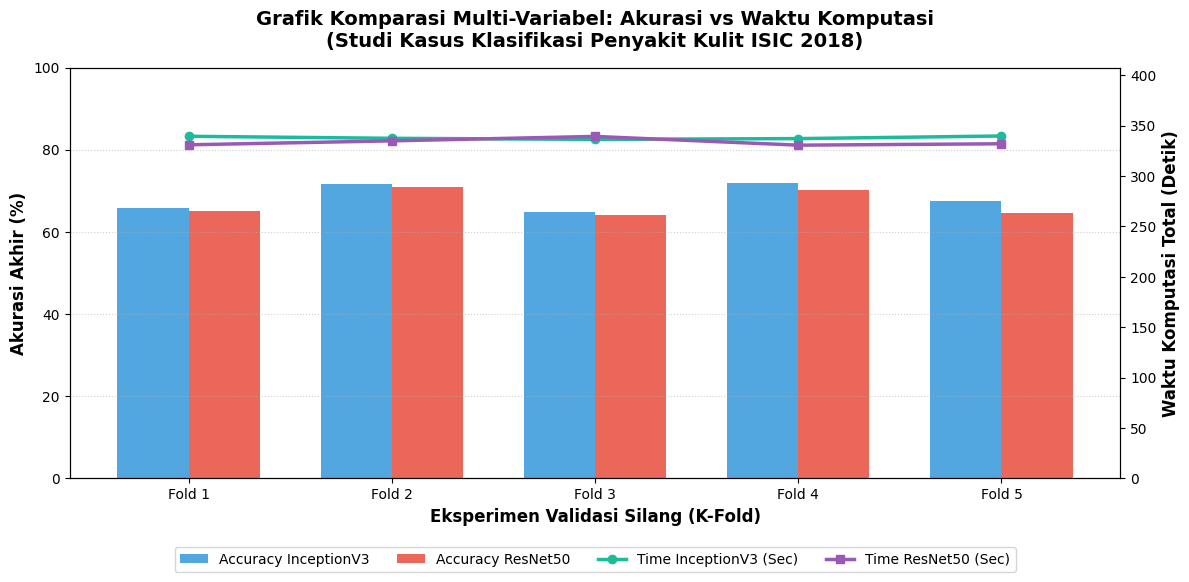

In [ ]:
# GRAND FINALE CHART - ACCURACY VS COMPUTATION TIME

folds = [f"Fold {i+1}" for i in range(5)]
x = np.arange(len(folds))

# Konversi akurasi ke persen untuk visualisasi yang ramah pembaca
inc_acc_percent = [a * 100 for a in inception_accuracies]
res_acc_percent = [a * 100 for a in resnet_accuracies]

# Mulai membuat plot dual-axis
fig, ax1 = plt.subplots(figsize=(12, 6))

# 1. SUMBU KIRI: Menggambar Batang Akurasi (%)
color1 = '#3498db' # Biru untuk Inception
color2 = '#e74c3c' # Merah untuk ResNet
width = 0.35

bar1 = ax1.bar(x - width/2, inc_acc_percent, width, label='Accuracy InceptionV3', color=color1, alpha=0.85)
bar2 = ax1.bar(x + width/2, res_acc_percent, width, label='Accuracy ResNet50', color=color2, alpha=0.85)

ax1.set_xlabel('Eksperimen Validasi Silang (K-Fold)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Akurasi Akhir (%)', fontsize=12, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(folds)
ax1.set_ylim(0, 100) # Batas persentase akurasi
ax1.grid(True, axis='y', linestyle=':', alpha=0.6)

# 2. SUMBU KANAN: Menggambar Garis Tren Waktu Komputasi (Detik)
ax2 = ax1.twinx()  # Membuat sumbu Y kedua yang berbagi sumbu X yang sama
color_time1 = '#1abc9c' # Hijau Toska untuk waktu Inception
color_time2 = '#9b59b6' # Ungu untuk waktu ResNet

line1 = ax2.plot(x, inception_times, color=color_time1, marker='o', linewidth=2.5, label='Time InceptionV3 (Sec)')
line2 = ax2.plot(x, resnet_times, color=color_time2, marker='s', linewidth=2.5, label='Time ResNet50 (Sec)')

ax2.set_ylabel('Waktu Komputasi Total (Detik)', fontsize=12, fontweight='bold')
ax2.set_ylim(0, max(max(inception_times), max(resnet_times)) * 1.2) # Skala dinamis untuk waktu

# 3. MERAPIKAN LEGEND (Keterangan Warna)
# Menggabungkan label dari bar chart (sumbu 1) dan line chart (sumbu 2)
bars, labels_bars = ax1.get_legend_handles_labels()
lines, labels_lines = ax2.get_legend_handles_labels()
ax1.legend(bars + lines, labels_bars + labels_lines, loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=4, fontsize=10)

plt.title('Grafik Komparasi Multi-Variabel: Akurasi vs Waktu Komputasi\n(Studi Kasus Klasifikasi Penyakit Kulit ISIC 2018)', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

In [ ]:
# STATISTICAL SIGNIFICANCE TEST (PAIRED T-TEST)

from scipy import stats

print("==========================================================================")
print("             UJI SIGNIFIKANSI STATISTIK (PAIRED T-TEST)")
print("==========================================================================")

# 1. Jalankan Paired t-Test untuk AKURASI
t_stat_acc, p_val_acc = stats.ttest_rel(inception_accuracies, resnet_accuracies)

print(f"[VARIABEL AKURASI]")
print(f"-> Nilai T-Statistic : {t_stat_acc:.4f}")
print(f"-> Nilai P-Value     : {p_val_acc:.4f}")

# Keputusan Ilmiah Akurasi (Alpha = 0.05)
if p_val_acc < 0.05:
    print("KESIMPULAN: Ada PERBEDAAN SIGNIFIKAN secara statistik pada akurasi kedua model! (Bukan kebetulan)")
else:
    print("KESIMPULAN: TIDAK ADA perbedaan signifikan secara statistik pada akurasi. Performa keduanya setara!")

print("-" * 50)

# 2. Jalankan Paired t-Test untuk WAKTU KOMPUTASI
t_stat_time, p_val_time = stats.ttest_rel(inception_times, resnet_times)

print(f"[VARIABEL WAKTU KOMPUTASI]")
print(f"-> Nilai T-Statistic : {t_stat_time:.4f}")
print(f"-> Nilai P-Value     : {p_val_time:.4f}")

# Keputusan Ilmiah Waktu (Alpha = 0.05)
if p_val_time < 0.05:
    print("KESIMPULAN: Ada PERBEDAAN SIGNIFIKAN secara statistik pada kecepatan komputasi kedua model!")
else:
    print("KESIMPULAN: TIDAK ADA perbedaan signifikan pada kecepatan. Waktu proses keduanya setara secara statistik.")
print("==========================================================================")


             UJI SIGNIFIKANSI STATISTIK (PAIRED T-TEST)
[VARIABEL AKURASI]
-> Nilai T-Statistic : 3.1502
-> Nilai P-Value     : 0.0345
KESIMPULAN: Ada PERBEDAAN SIGNIFIKAN secara statistik pada akurasi kedua model! (Bukan kebetulan)
--------------------------------------------------
[VARIABEL WAKTU KOMPUTASI]
-> Nilai T-Statistic : 2.1080
-> Nilai P-Value     : 0.1027
KESIMPULAN: TIDAK ADA perbedaan signifikan pada kecepatan. Waktu proses keduanya setara secara statistik.
